In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from energia import config, features
from energia.features import COVARIABLES_FUTURAS, COVARIABLES_PASADAS
from energia.io import cargar_tabla, guardar_tabla
from energia.dataset import Escalador, cargar_datos_modelo
from energia.metricas import evaluar, error_por_hora, naive_estacional, tabla
from energia.visualizacion import estilo, guardar_figura

estilo()

In [2]:
horario = cargar_tabla(config.ARCHIVO_HORARIO)
df = features.construir_features(horario)
print(df.shape, df.index.min(), df.index.max())

(40704, 16) 2022-01-09 00:00:00 2026-08-31 23:00:00


In [3]:
grupos = pd.Series({
    **{c: "objetivo" for c in config.OBJETIVOS},
    **{c: "covariable_pasada" for c in COVARIABLES_PASADAS},
    **{c: "covariable_futura" for c in COVARIABLES_FUTURAS},
}, name="grupo")
grupos.to_frame().join(df.describe().T[["mean", "std", "min", "max"]])

,grupo,mean,std,min,max
demanda_kwh,objetivo,2.922079e+06,2.753058e+05,1.681983e+06,3.664484e+06
precio_bolsa_cop_kwh,objetivo,4.285511e+02,3.563325e+02,8.905597e+01,2.675650e+03
precio_contrato_cop_kwh,covariable_pasada,2.867341e+02,1.989294e+01,2.382965e+02,3.836601e+02
aportes_kwh_d1,covariable_pasada,2.063042e+08,9.178999e+07,5.579500e+07,6.430755e+08
aportes_media7_kwh_d1,covariable_pasada,2.061388e+08,8.284806e+07,5.813913e+07,5.055218e+08
volumen_util_kwh_d1,covariable_pasada,1.189720e+10,2.380275e+09,4.958518e+09,1.564980e+10
volumen_util_delta7_kwh_d1,covariable_pasada,2.420428e+06,3.440979e+08,-8.206502e+08,1.018792e+09
hora_sin,covariable_futura,-5.623080e-10,7.071155e-01,-1.000000e+00,1.000000e+00
hora_cos,covariable_futura,-5.623080e-10,7.071155e-01,-1.000000e+00,1.000000e+00
dia_semana_sin,covariable_futura,-4.609848e-04,7.069532e-01,-9.749279e-01,9.749279e-01


In [4]:
diario = horario[config.EXOGENAS_DIARIAS].resample("D").first()
sufijo = f"_d{config.REZAGO_EXOGENAS_DIARIAS}"
for col in config.EXOGENAS_DIARIAS:
    esperado = diario[col].shift(config.REZAGO_EXOGENAS_DIARIAS).reindex(df.index.normalize()).to_numpy()
    assert np.allclose(df[col + sufijo].to_numpy(), esperado, rtol=1e-6)
assert set(COVARIABLES_FUTURAS) <= set(features.agregar_calendario(df.iloc[:5]).columns)

In [5]:
festivos = df.loc[df["es_festivo"] == 1].index.normalize().unique()
len(festivos), [d.strftime("%Y-%m-%d") for d in festivos[:6]]

(83,
 ['2022-01-10',
  '2022-03-21',
  '2022-04-14',
  '2022-04-15',
  '2022-05-01',
  '2022-05-30'])

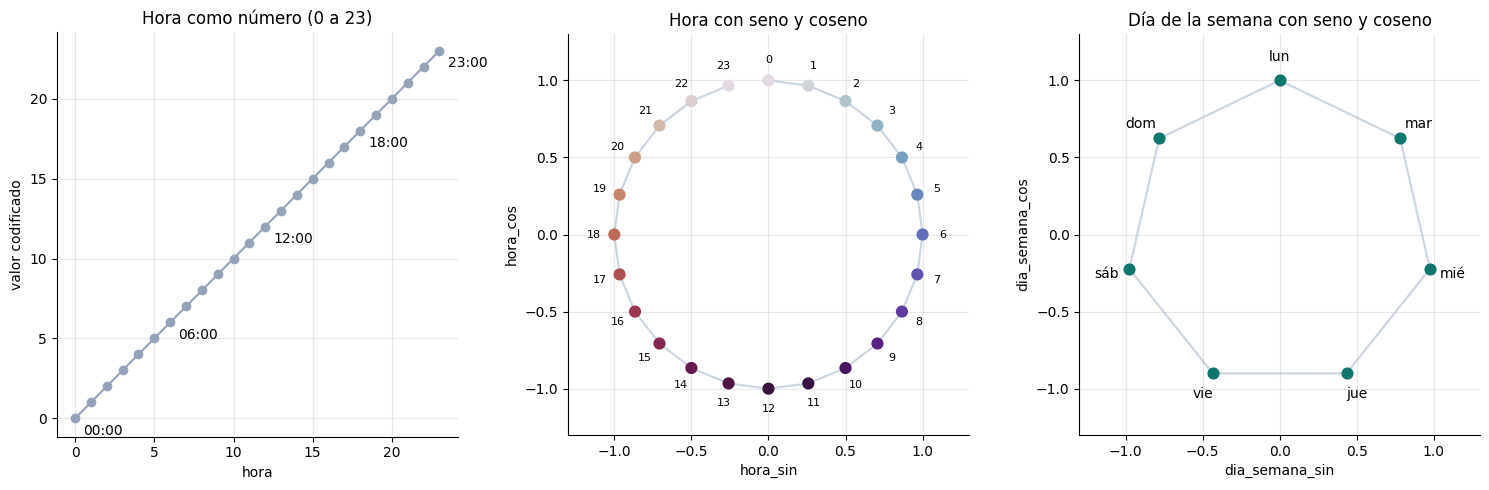

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

horas = np.arange(24)
axes[0].plot(horas, horas, "o-", color="#94a3b8")
for hr in (0, 6, 12, 18, 23):
    axes[0].annotate(f"{hr:02d}:00", (hr, hr), textcoords="offset points", xytext=(6, -12))
axes[0].set(xlabel="hora", ylabel="valor codificado", title="Hora como número (0 a 23)")

ang = 2 * np.pi * horas / 24
axes[1].plot(np.sin(ang), np.cos(ang), color="#cbd5e1", zorder=1)
sc = axes[1].scatter(np.sin(ang), np.cos(ang), c=horas, cmap="twilight", s=60, zorder=2)
for hr in range(24):
    axes[1].annotate(f"{hr}", (np.sin(ang[hr]) * 1.13, np.cos(ang[hr]) * 1.13), ha="center", va="center", fontsize=8)
axes[1].set(xlabel="hora_sin", ylabel="hora_cos", title="Hora con seno y coseno", aspect="equal",
            xlim=(-1.3, 1.3), ylim=(-1.3, 1.3))

dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
ang_d = 2 * np.pi * np.arange(7) / 7
axes[2].plot(np.append(np.sin(ang_d), np.sin(ang_d[0])), np.append(np.cos(ang_d), np.cos(ang_d[0])), color="#cbd5e1", zorder=1)
axes[2].scatter(np.sin(ang_d), np.cos(ang_d), color="#0f766e", s=60, zorder=2)
for k, d in enumerate(dias):
    axes[2].annotate(d, (np.sin(ang_d[k]) * 1.15, np.cos(ang_d[k]) * 1.15), ha="center", va="center")
axes[2].set(xlabel="dia_semana_sin", ylabel="dia_semana_cos", title="Día de la semana con seno y coseno", aspect="equal",
            xlim=(-1.3, 1.3), ylim=(-1.3, 1.3))

fig.tight_layout()
guardar_figura(fig, "04_03_codificacion_ciclica")
plt.show()

In [7]:
guardar_tabla(df, config.ARCHIVO_FEATURES)

WindowsPath('C:/Users/57310/Desktop/pronostico-energia-nr/pronostico-energia-nr/data/processed/dataset_features.parquet')

In [8]:
esc = Escalador().ajustar(df.loc[: config.FIN_TRAIN])
esc.guardar()
pd.DataFrame({"media": esc.media, "desv": esc.desv, "log1p": {c: c in esc.log for c in esc.media}})

,media,desv,log1p
demanda_kwh,2.879158e+06,2.615591e+05,False
precio_bolsa_cop_kwh,5.815399e+00,7.917039e-01,True
precio_contrato_cop_kwh,2.825040e+02,1.932224e+01,False
aportes_kwh_d1,1.901555e+01,5.024689e-01,True
aportes_media7_kwh_d1,1.902607e+01,4.776642e-01,True
volumen_util_kwh_d1,1.146888e+10,2.509447e+09,False
volumen_util_delta7_kwh_d1,4.509341e+06,3.712438e+08,False


In [9]:
datos = cargar_datos_modelo()
datos.resumen()

,muestras,pasado,futuro,y,primer_t0,ultimo_t0
split,,,,,,
train,30265,"(30265, 168, 16)","(30265, 24, 9)","(30265, 24, 2)",2022-01-16,2025-06-30
val,184,"(184, 168, 16)","(184, 24, 9)","(184, 24, 2)",2025-07-01,2025-12-31
test,243,"(243, 168, 16)","(243, 24, 9)","(243, 24, 2)",2026-01-01,2026-08-31


In [10]:
for sp in datos.splits.values():
    assert not np.isnan(sp.pasado).any() and not np.isnan(sp.y).any()
assert (datos.splits["train"].t0 + pd.Timedelta(hours=23)).max() <= pd.Timestamp(config.FIN_TRAIN)
assert datos.splits["val"].t0.min() > pd.Timestamp(config.FIN_TRAIN)
assert datos.splits["test"].t0.min() > pd.Timestamp(config.FIN_VAL)
assert (datos.splits["val"].t0.hour == 0).all() and (datos.splits["test"].t0.hour == 0).all()

y_val = datos.y_original("val")
t0 = datos.splits["val"].t0[0]
crudo = horario.loc[t0 : t0 + pd.Timedelta(hours=23), config.OBJETIVOS].to_numpy()
float(np.max(np.abs(y_val[0] - crudo) / crudo))

5.5502768733575104e-08

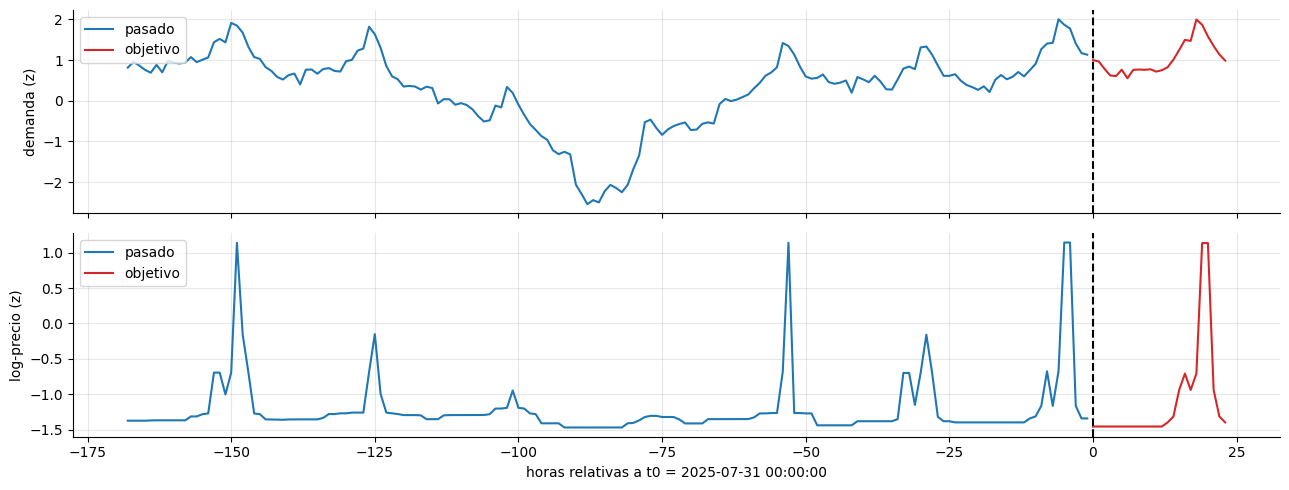

In [11]:
i = 30
sp = datos.splits["val"]
fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
for j, (ax, nombre) in enumerate(zip(axes, ["demanda (z)", "log-precio (z)"])):
    ax.plot(range(-datos.ventana, 0), sp.pasado[i, :, j], label="pasado")
    ax.plot(range(0, datos.horizonte), sp.y[i, :, j], label="objetivo", color="C3")
    ax.axvline(0, color="k", ls="--")
    ax.set_ylabel(nombre)
    ax.legend(loc="upper left")
axes[1].set_xlabel(f"horas relativas a t0 = {sp.t0[i]}")
fig.tight_layout()
guardar_figura(fig, "04_01_ejemplo_ventana")
plt.show()

In [12]:
resultados, predicciones = {}, {}
for split in ["val", "test"]:
    y = datos.y_original(split)
    for m in (24, 168):
        p = naive_estacional(datos, split, m=m)
        predicciones[(f"naive_m{m}", split)] = p
        resultados[(f"naive_m{m}", split)] = evaluar(y, p)
lineas_base = tabla(resultados)
lineas_base.index = pd.MultiIndex.from_tuples(lineas_base.index, names=["modelo", "split"])
lineas_base

,,demanda_MAE,precio_MAE,demanda_RMSE,precio_RMSE,demanda_MAPE_%,precio_MAPE_%,demanda_R2,precio_R2
modelo,split,,,,,,,,
naive_m24,val,194135.892010,48.523627,274407.867423,111.794765,6.718642,20.336838,-0.075762,0.475988
naive_m168,val,111762.365881,81.734684,179377.523882,136.076668,3.833292,37.448509,0.540316,0.223636
naive_m24,test,194816.646206,56.109531,273062.870794,111.123112,6.670997,14.863168,0.069204,0.881077
naive_m168,test,121128.936093,126.488172,201826.283211,182.248794,4.059732,34.665457,0.491508,0.680121


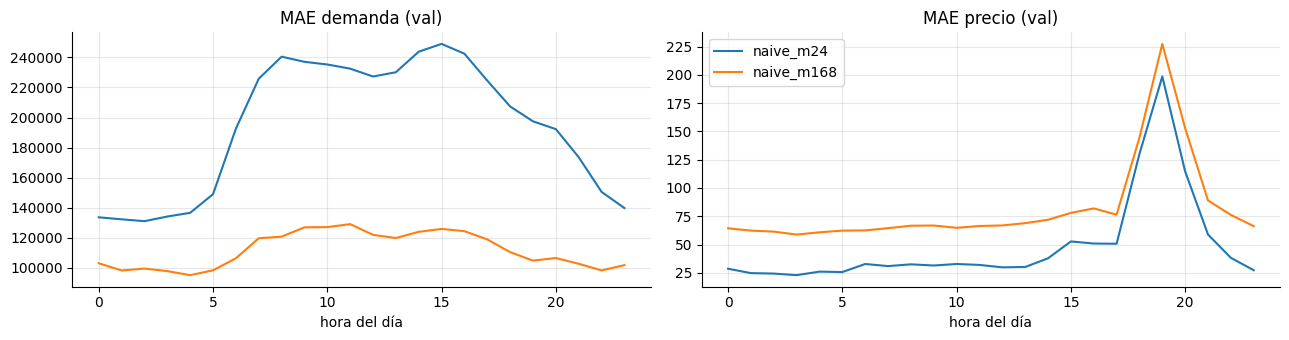

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for nombre in ["naive_m24", "naive_m168"]:
    e = error_por_hora(datos.y_original("val"), predicciones[(nombre, "val")])
    e.index = e.index - 1
    axes[0].plot(e.index, e["demanda"], label=nombre)
    axes[1].plot(e.index, e["precio"], label=nombre)
axes[0].set(title="MAE demanda (val)", xlabel="hora del día")
axes[1].set(title="MAE precio (val)", xlabel="hora del día")
axes[1].legend()
fig.tight_layout()
guardar_figura(fig, "04_02_linea_base_error_por_hora")
plt.show()